# 02 - Clean and split

This notebook audits the raw data, records a decision for every problem found, splits the trips by month and runs the analysis the brief asks for question C.

The cleaning itself lives in `src/data.py` (`load_trips()`), so every notebook rebuilds exactly the same table from the raw file. The audit looks at May only: exploring the months we validate and test on would let what we see there shape our decisions.

In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from src.data import RAW_PATH, load_trips

RAW_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Audit

We load the raw file and keep only May. Duration is computed here too, because several problems are about it.

In [ ]:
raw = pd.read_parquet(RAW_PATH)
raw["duration_min"] = (raw["tpep_dropoff_datetime"] - raw["tpep_pickup_datetime"]).dt.total_seconds() / 60

may = raw[raw["tpep_pickup_datetime"].dt.month == 5]
print("May raw trips:", len(may))

checks = {
    "duration under 1 min": (may["duration_min"] < 1).sum(),
    "duration over 120 min": (may["duration_min"] > 120).sum(),
    "distance of 0 miles": (may["trip_distance"] == 0).sum(),
    "distance over 40 miles": (may["trip_distance"] > 40).sum(),
    "negative fare or total": ((may["fare_amount"] < 0) | (may["total_amount"] < 0)).sum(),
    "passenger_count missing": may["passenger_count"].isna().sum(),
    "passenger_count = 0": (may["passenger_count"] == 0).sum(),
    "unknown pickup zone (264, 265)": may["PULocationID"].isin([264, 265]).sum(),
    "unknown drop-off zone (264, 265)": may["DOLocationID"].isin([264, 265]).sum(),
    "non-standard RatecodeID (not 1)": (may["RatecodeID"].notna() & (may["RatecodeID"] != 1)).sum(),
    "request_source filled": may["request_source"].notna().sum(),
    "duplicated rows": may.duplicated().sum(),
}
pd.Series(checks, name="May trips")

May raw trips: 199999


duration under 1 min                 4673
duration over 120 min                 277
distance of 0 miles                  5532
distance over 40 miles                 71
negative fare or total                713
passenger_count missing             46601
passenger_count = 0                   622
unknown pickup zone (264, 265)        329
unknown drop-off zone (264, 265)     1103
non-standard RatecodeID (not 1)     14241
request_source filled                   0
duplicated rows                         0
Name: May trips, dtype: int64

`request_source` is empty in all of May. Let's check the other months.

In [ ]:
month = raw["tpep_pickup_datetime"].dt.month
raw.groupby(month)["request_source"].apply(lambda s: s.notna().mean()).round(3)

tpep_pickup_datetime
4    0.000
5    0.000
6    0.264
7    0.275
Name: request_source, dtype: float64

It only appears from June, in about 27% of the trips. A column that shows up halfway through the data is dangerous: a model trained on May would learn it as always empty, and then meet it filled in June and July. It is also undocumented in the data dictionary, so we do not use it.

# Findings and decisions

Every problem gets one decision: **drop** the trip, **fix** the value, or **flag** it (keep the trip and write it down). None of the decisions learns a number from the data; they are all fixed rules.

| Problem (May) | Decision | Why |
|---|---|---|
| Duration under 1 minute (4,673) | Drop | Meters switched on and off, or voided trips. The speed means nothing |
| Duration over 120 minutes (277) | Drop | Mostly meters left running. Their very low speed would be labelled as a crawl |
| Distance of 0 miles (5,532) | Drop | A speed of 0 would be labelled as a crawl, although the taxi never moved |
| Distance over 40 miles (71) | Drop | Absurd values. Real trips that long are very rare |
| Speed of 70 mph or more | Drop | Each value is plausible alone, the combination is not |
| Pickup outside May to July (2 trips, in April) | Drop | They belong to no split |
| Negative fare or total (713) | Flag | Refunds and disputes. The target only uses time and distance, which still look plausible, and no amount is a model input |
| `passenger_count` missing (46,601, all the flex fares) | Flag | To be handled in the features pipeline, if the column is used |
| `passenger_count` = 0 (622) | Flag | Not a real value. Treated like a missing value if the column is used |
| Unknown zones 264 and 265 (329 pickups, 1,103 drop-offs) | Flag | The zone is a category, and "unknown" is just one more category the model can learn |
| Non-standard fares, `RatecodeID` not 1 (14,241) | Flag | Real trips: airport flat fares, negotiated fares, code 99. `RatecodeID` is settled at the end of the trip, so it is never a model input |
| Flex fares, `payment_type` 0 (46,601) | Flag | The dispatcher faces them in practice. Explained in `01-frame` |
| `request_source` (empty in May) | Not used | Undocumented, and it appears halfway through the data |
| Duplicated rows (0) | Nothing to do | |

The drop decisions are the filters of `01-frame`, and they live in `load_trips()`.

# The split

May trains, June validates, July tests. `load_trips()` applies the drop decisions and adds the `split` column.

In [ ]:
trips = load_trips()
train = trips[trips["split"] == "train"]
valid = trips[trips["split"] == "valid"]

trips.groupby("split").agg(trips=("is_crawl", "size"), positive_rate=("is_crawl", "mean")).round(3)

,trips,positive_rate
split,,
test,189444,0.168
train,190878,0.197
valid,190003,0.190


**Is the positive rate stable?** Not completely: 19.7% in May, 19.0% in June and 16.8% in July. Crawls get rarer as the summer goes on.

This is the only look at July before the final evaluation, and it only counts labels, it does not score a model. The brief asks for it.

Two consequences:
- A threshold chosen on June may flag a few too many trips in July.
- Precision measured on June will probably be a little optimistic for July.

# When do trips crawl?

By hour of the day and by day of the week, May against June.

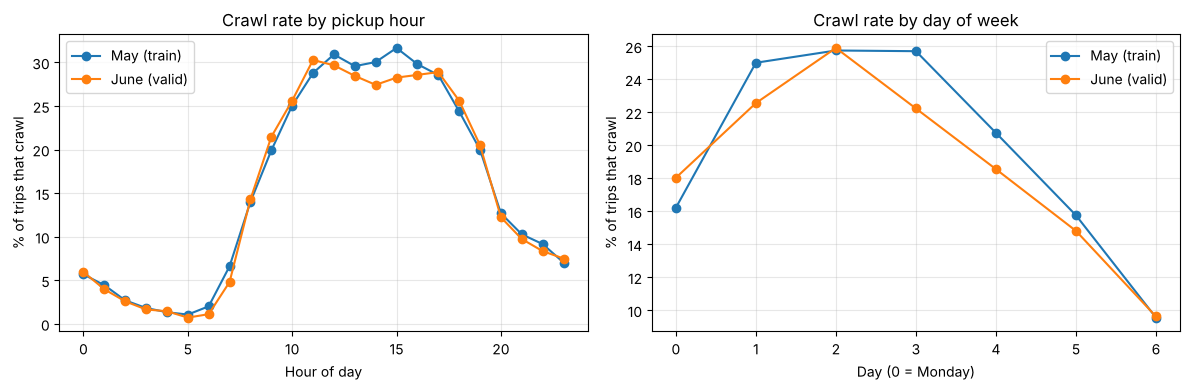

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for df, label in [(train, "May (train)"), (valid, "June (valid)")]:
    pickup = df["tpep_pickup_datetime"]
    df.groupby(pickup.dt.hour)["is_crawl"].mean().mul(100).plot(ax=axes[0], marker="o", label=label)
    df.groupby(pickup.dt.day_of_week)["is_crawl"].mean().mul(100).plot(ax=axes[1], marker="o", label=label)

axes[0].set(title="Crawl rate by pickup hour", xlabel="Hour of day", ylabel="% of trips that crawl")
axes[1].set(title="Crawl rate by day of week", xlabel="Day (0 = Monday)", ylabel="% of trips that crawl")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "crawl_rate_hour_weekday.png", dpi=150)
plt.show()

Crawling is a daytime, weekday problem. It stays under 7% at night and rises to around 30% from late morning to late afternoon. Tuesday to Thursday are the worst days (about 25%), Sunday the best (under 10%).

May and June follow the same shape, so the pattern is stable from one month to the next.

# Where do trips crawl?

The crawl rate by pickup zone in May. Zones with fewer than 200 May pickups are left grey, because a rate computed on a few trips is mostly noise.

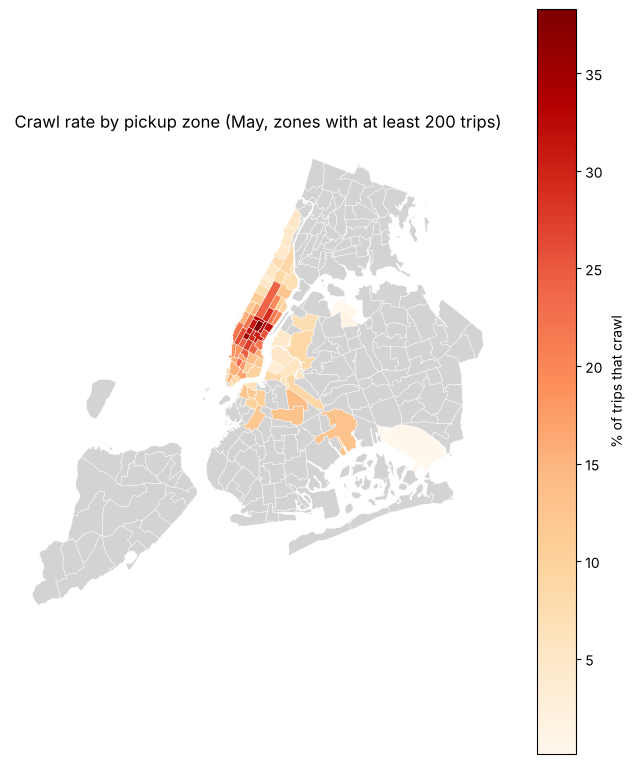

In [ ]:
zones = gpd.read_file(RAW_DIR / "taxi_zones" / "taxi_zones.shp")

zone_stats = train.groupby("PULocationID")["is_crawl"].agg(trips="size", crawl_rate="mean")
zone_stats.loc[zone_stats["trips"] < 200, "crawl_rate"] = float("nan")
zone_stats["crawl_rate"] = zone_stats["crawl_rate"] * 100

zmap = zones.merge(zone_stats, left_on="LocationID", right_index=True, how="left")

fig, ax = plt.subplots(figsize=(8, 10))
zmap.plot(
    column="crawl_rate",
    cmap="OrRd",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.3,
    missing_kwds={"color": "lightgrey"},
    legend_kwds={"label": "% of trips that crawl"},
)
ax.set_title("Crawl rate by pickup zone (May, zones with at least 200 trips)")
ax.set_axis_off()

plt.savefig(FIG_DIR / "crawl_rate_zone_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
(zmap[zmap["crawl_rate"].notna()]
    [["LocationID", "zone", "borough", "trips", "crawl_rate"]]
    .sort_values("crawl_rate", ascending=False)
    .head(10)
    .round({"crawl_rate": 1}))

,LocationID,zone,borough,trips,crawl_rate
160,161,Midtown Center,Manhattan,7746.0,38.3
185,186,Penn Station/Madison Sq West,Manhattan,5410.0,35.2
162,163,Midtown North,Manhattan,4627.0,33.1
161,162,Midtown East,Manhattan,5693.0,32.8
228,229,Sutton Place/Turtle Bay North,Manhattan,3079.0,32.2
99,100,Garment District,Manhattan,2380.0,32.1
229,230,Times Sq/Theatre District,Manhattan,5246.0,31.0
169,170,Murray Hill,Manhattan,4878.0,30.6
163,164,Midtown South,Manhattan,3501.0,29.4
236,237,Upper East Side South,Manhattan,9485.0,29.0


Crawling concentrates in Midtown Manhattan: the ten worst pickup zones are all there, led by Midtown Center (38%).

# Which trips crawl?

The brief asks three questions: short or long trips, within Manhattan or across boroughs, to or from airports.

To know the borough of each zone we use the lookup table. The airports are zones 1 (Newark), 132 (JFK) and 138 (LaGuardia).

In [ ]:
lookup = pd.read_csv(RAW_DIR / "taxi_zone_lookup.csv").set_index("LocationID")["Borough"]
pu_borough = train["PULocationID"].map(lookup)
do_borough = train["DOLocationID"].map(lookup)
airport = train["PULocationID"].isin([1, 132, 138]) | train["DOLocationID"].isin([1, 132, 138])

kind = pd.Series("within another borough", index=train.index)
kind[(pu_borough == "Manhattan") & (do_borough == "Manhattan")] = "within Manhattan"
kind[pu_borough != do_borough] = "across boroughs"
kind[airport] = "to or from an airport"

train.groupby(kind)["is_crawl"].agg(trips="size", positive_rate="mean").round(3)

,trips,positive_rate
across boroughs,16827,0.037
to or from an airport,15231,0.004
within Manhattan,153192,0.235
within another borough,5628,0.155


In [ ]:
distance_band = pd.cut(train["trip_distance"], [0, 0.5, 1, 2, 5, 10, 40])
train.groupby(distance_band, observed=True)["is_crawl"].agg(trips="size", positive_rate="mean").round(3)

,trips,positive_rate
trip_distance,,
"(0.0, 0.5]",8974,0.569
"(0.5, 1.0]",32117,0.359
"(1.0, 2.0]",57218,0.255
"(2.0, 5.0]",55187,0.109
"(5.0, 10.0]",22936,0.014
"(10.0, 40.0]",14446,0.001


**Short trips inside Manhattan crawl. Long trips and airport trips almost never do.**

- Within Manhattan, 23.5% of the trips crawl. Across boroughs, 3.7%. To or from an airport, 0.4%.
- More than half of the trips under half a mile crawl (57%), against almost none above 5 miles.

A short trip spends a big part of its time on things that do not depend on distance: traffic lights, the passenger getting in and out, finding a place to stop. So its average speed is low. Long trips use avenues, bridges and highways.

# Conclusion

- **5% of the trips are dropped** because their speed cannot be trusted. Everything else is kept, and the odd cases are written down in the findings table.
- **The positive rate drifts down** from 19.7% in May to 16.8% in July.
- **Time, place and distance all matter:** crawls happen in the day, on weekdays, in Midtown, and on short trips.

These three overlap: Midtown trips are short and happen during the day. The features notebook checks what each one adds on June.